### Resolução de Labirintos com Algoritmos de Busca

Este notebook atua como o **compilador/leitor do labirinto** (lendo os arquivos `.txt`, gerando as visualizações em texto e imagem).

Os algoritmos de busca são consumidos a partir do módulo `maze_algorithms.py` como uma biblioteca modular.

In [97]:
from PIL import Image, ImageDraw
from IPython.display import Image as IPImage, display
import maze_algorithms

class Maze:
    """Classe responsável por interpretar e desenhar o labirinto a partir de um arquivo texto."""

    def __init__(self, filename):
        # Lê o arquivo do labirinto
        with open(filename, "r", encoding="utf-8") as f:
            contents = f.read()

        # Valida ponto inicial (A) e objetivo (B)
        if contents.count("A") != 1:
            raise Exception("O labirinto deve conter exatamente um ponto de partida ('A').")
        if contents.count("B") != 1:
            raise Exception("O labirinto deve conter exatamente um objetivo ('B').")

        # Determina dimensões da matriz
        lines = contents.splitlines()
        self.height = len(lines)
        self.width = max(len(line) for line in lines)

        # Mapeia as paredes e posições de início/fim
        self.walls = []
        for i in range(self.height):
            row = []
            for j in range(self.width):
                try:
                    char = lines[i][j]
                    if char == "A":
                        self.start = (i, j)
                        row.append(False)
                    elif char == "B":
                        self.goal = (i, j)
                        row.append(False)
                    elif char == " ":
                        row.append(False)
                    else:
                        row.append(True)
                except IndexError:
                    row.append(False)
            self.walls.append(row)

        self.solution = None
        self.num_explored = 0
        self.explored = set()
        self.method = None

    def print(self):
        """Exibe a visualização textual do labirinto com a solução (se encontrada)."""
        solution = self.solution[1] if self.solution is not None else None
        print()
        for i, row in enumerate(self.walls):
            for j, col in enumerate(row):
                if col:
                    print("█", end="")
                elif (i, j) == self.start:
                    print("A", end="")
                elif (i, j) == self.goal:
                    print("B", end="")
                elif solution is not None and (i, j) in solution:
                    print("*", end="")
                else:
                    print(" ", end="")
            print()
        print()

    def neighbors(self, state):
        """Retorna os vizinhos válidos e desobstruídos a partir de uma coordenada (linha, coluna)."""
        row, col = state
        candidates = [
            ("up", (row - 1, col)),
            ("down", (row + 1, col)),
            ("left", (row, col - 1)),
            ("right", (row, col + 1))
        ]

        result = []
        for action, (r, c) in candidates:
            if 0 <= r < self.height and 0 <= c < self.width and not self.walls[r][c]:
                result.append((action, (r, c)))
        return result

    def solve(self, method="dfs"):
        """
        Chama a biblioteca maze_algorithms para resolver o labirinto.
        method
        """
        self.method = method.lower()
        self.solution, self.num_explored, self.explored = maze_algorithms.solve_maze_search(
            start=self.start,
            goal=self.goal,
            neighbors_fn=self.neighbors,
            method=self.method
        )

    def output_image(self, filename="maze.png", show_solution=True, show_explored=True):
        """Renderiza graficamente o labirinto e salva em um arquivo de imagem."""
        cell_size = 50
        cell_border = 2

        img = Image.new(
            "RGBA",
            (self.width * cell_size, self.height * cell_size),
            "black"
        )
        draw = ImageDraw.Draw(img)

        solution = self.solution[1] if self.solution is not None else None
        for i, row in enumerate(self.walls):
            for j, col in enumerate(row):
                # Parede
                if col:
                    fill = (40, 40, 40)
                # Ponto de Partida
                elif (i, j) == self.start:
                    fill = (255, 0, 0)
                # Objetivo
                elif (i, j) == self.goal:
                    fill = (0, 171, 28)
                # Caminho da Solução
                elif solution is not None and show_solution and (i, j) in solution:
                    fill = (220, 235, 113)
                # Células exploradas durante a busca
                elif self.explored is not None and show_explored and (i, j) in self.explored:
                    fill = (212, 97, 85)
                # Célula vazia não explorada
                else:
                    fill = (237, 240, 252)

                draw.rectangle(
                    [(
                        j * cell_size + cell_border,
                        i * cell_size + cell_border
                    ),
                    (
                        (j + 1) * cell_size - cell_border,
                        (i + 1) * cell_size - cell_border
                    )],
                    fill=fill
                )

        img.save(filename)


### Função Executora Principal

A função `solve_maze` unifica a experiência:
1. Lê o arquivo do labirinto (`.txt`).
2. Mostra a estrutura inicial.
3. Executa a solução com o método escolhido.
4. Exibe a contagem de estados explorados e o desenho da solução no texto.
5. Renderiza e exibe a imagem resultante diretamente no notebook.

In [98]:
def solve_maze(filename, method="dfs", show_image=True):
    """
    Lê o labirinto, resolve com o método especificado e exibe o resultado.
    """
    m = Maze(filename)
    print(f"=== Labirinto: {filename} ===")
    print("Maze Inicial:")
    m.print()

    print(f"Solving with {method.upper()}...")
    m.solve(method=method)
    print("States Explored:", m.num_explored)
    if m.solution is not None:
        cost = len(m.solution[0])
        print("Path Cost:", cost)
    else:
        print("No solution found.")
    print("Solution:")
    m.print()

    if show_image:
        image_name = f"{filename.replace('.txt', '').replace('/','/logs/')}_{method.lower()}.png"
        m.output_image(image_name, show_explored=True)
        display(IPImage(filename=image_name))

    return m


### Comparando os algoritimos

Compare a quantidade de estados explorados e o caminho entre **DFS**, **BFS**, **GBFS** e **ASTAR**:

=== Labirinto: data/maze3.txt ===
Maze Inicial:

A█       █     █                 
 █ █████ █ ███ █ █████ █ ████████
   █   █   █   █ █     █ █     █ 
 ███ █ █████ ███ █ █████ █ ███ █ 
     █     █   █ █ █   █     █ █ 
 █████████ ███ █ █ █ ███████ █ █ 
 █       █   █   █ █ █       █ █ 
 █ █████ ███ █████ █ █ █████ █ █ 
 █   █     █       █ █     █ █ █ 
 ███ █ █████ ███ █ █ ███ █ █ █   
   █ █ █     █   █ █   █   █ █ █ 
██ █ █ █ █████ ███ ███ █████ █ █ 
   █ █ █     █   █   █     █ █ █ 
 ███ █ █████ ███ ███ █████ █ █ █ 
   █ █     █   █   █     █ █ █ █ 
██ █ █████ ███ ███ █████ █ █ █ █ 
   █     █   █   █     █   █   █ 
 ███████ ███ ███ █████ ███████ █ 
         █   █                 █B

Solving with DFS...
States Explored: 323
Path Cost: 88
Solution:

A█*******█*****█*********        
*█*█████*█*███*█*█████ █*████████
***█   █***█***█*█     █*█     █ 
 ███ █ █████*███*█ █████*█ ███ █ 
     █     █***█*█ █   █*****█ █ 
 █████████ ███*█*█ █ ███████*█ █ 
 █       █   █***█ █ █      *█ █ 


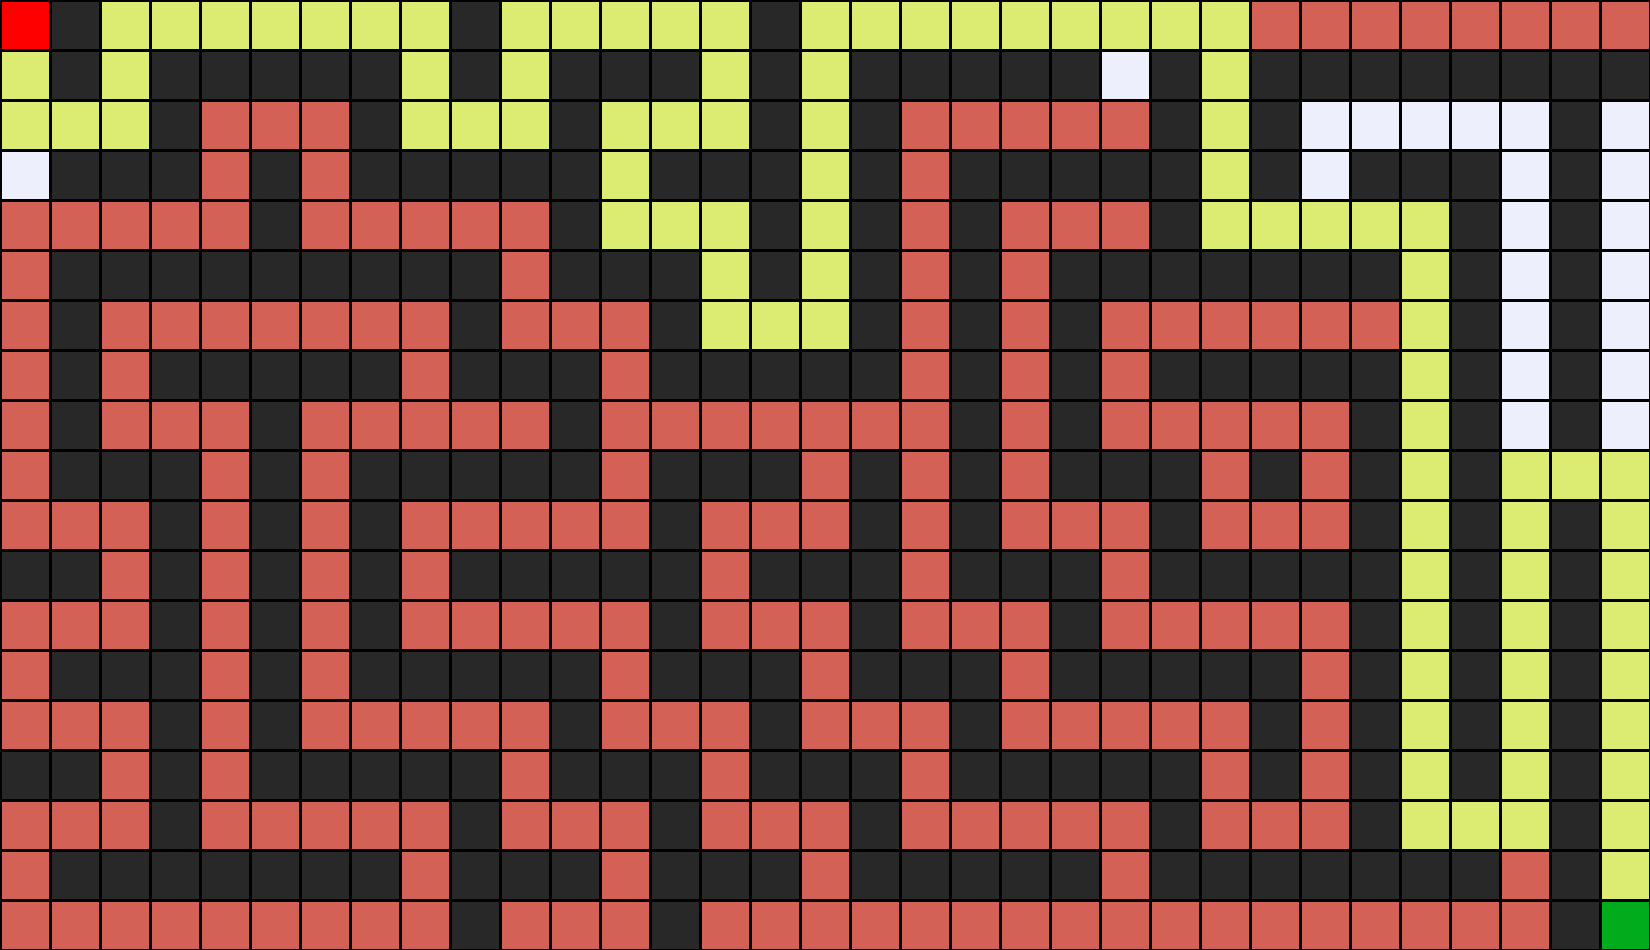

In [99]:
# Define o maze a ser comparado
maze_txt = "data/maze3.txt"
# DFS
m2_dfs = solve_maze(maze_txt, method="dfs")


=== Labirinto: data/maze3.txt ===
Maze Inicial:

A█       █     █                 
 █ █████ █ ███ █ █████ █ ████████
   █   █   █   █ █     █ █     █ 
 ███ █ █████ ███ █ █████ █ ███ █ 
     █     █   █ █ █   █     █ █ 
 █████████ ███ █ █ █ ███████ █ █ 
 █       █   █   █ █ █       █ █ 
 █ █████ ███ █████ █ █ █████ █ █ 
 █   █     █       █ █     █ █ █ 
 ███ █ █████ ███ █ █ ███ █ █ █   
   █ █ █     █   █ █   █   █ █ █ 
██ █ █ █ █████ ███ ███ █████ █ █ 
   █ █ █     █   █   █     █ █ █ 
 ███ █ █████ ███ ███ █████ █ █ █ 
   █ █     █   █   █     █ █ █ █ 
██ █ █████ ███ ███ █████ █ █ █ █ 
   █     █   █   █     █   █   █ 
 ███████ ███ ███ █████ ███████ █ 
         █   █                 █B

Solving with BFS...
States Explored: 338
Path Cost: 74
Solution:

A█       █     █      ***        
*█ █████ █ ███ █ █████*█*████████
*  █***█   █   █ █*****█*█*****█ 
*███*█*█████ ███ █*█████*█*███*█ 
*****█*****█   █ █*█   █***  █*█ 
 █████████*███ █ █*█ ███████ █*█ 
 █       █***█   █*█ █       █*█ 


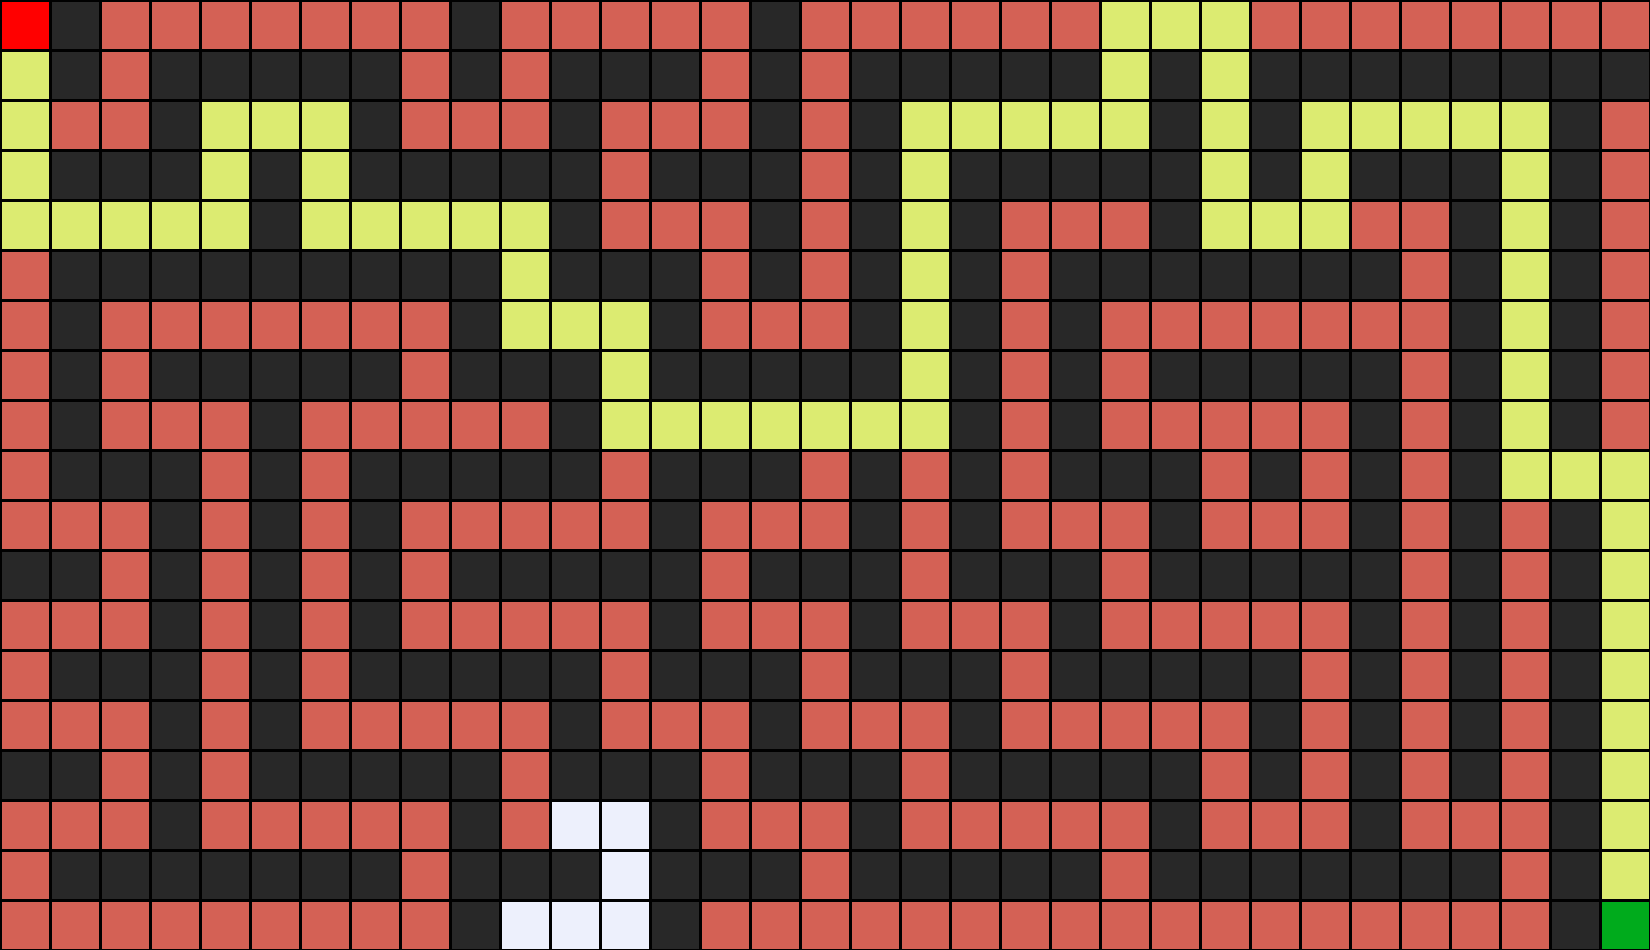

In [100]:
# BFS
m2_bfs = solve_maze(maze_txt, method="bfs")


=== Labirinto: data/maze3.txt ===
Maze Inicial:

A█       █     █                 
 █ █████ █ ███ █ █████ █ ████████
   █   █   █   █ █     █ █     █ 
 ███ █ █████ ███ █ █████ █ ███ █ 
     █     █   █ █ █   █     █ █ 
 █████████ ███ █ █ █ ███████ █ █ 
 █       █   █   █ █ █       █ █ 
 █ █████ ███ █████ █ █ █████ █ █ 
 █   █     █       █ █     █ █ █ 
 ███ █ █████ ███ █ █ ███ █ █ █   
   █ █ █     █   █ █   █   █ █ █ 
██ █ █ █ █████ ███ ███ █████ █ █ 
   █ █ █     █   █   █     █ █ █ 
 ███ █ █████ ███ ███ █████ █ █ █ 
   █ █     █   █   █     █ █ █ █ 
██ █ █████ ███ ███ █████ █ █ █ █ 
   █     █   █   █     █   █   █ 
 ███████ ███ ███ █████ ███████ █ 
         █   █                 █B

Solving with GBFS...
States Explored: 200
Path Cost: 76
Solution:

A█       █     █                 
*█ █████ █ ███ █ █████ █ ████████
*  █***█   █   █ █     █ █     █ 
*███*█*█████ ███ █ █████ █ ███ █ 
*****█*****█   █ █ █   █     █ █ 
 █████████*███ █ █ █ ███████ █ █ 
 █       █***█   █ █ █       █ █ 

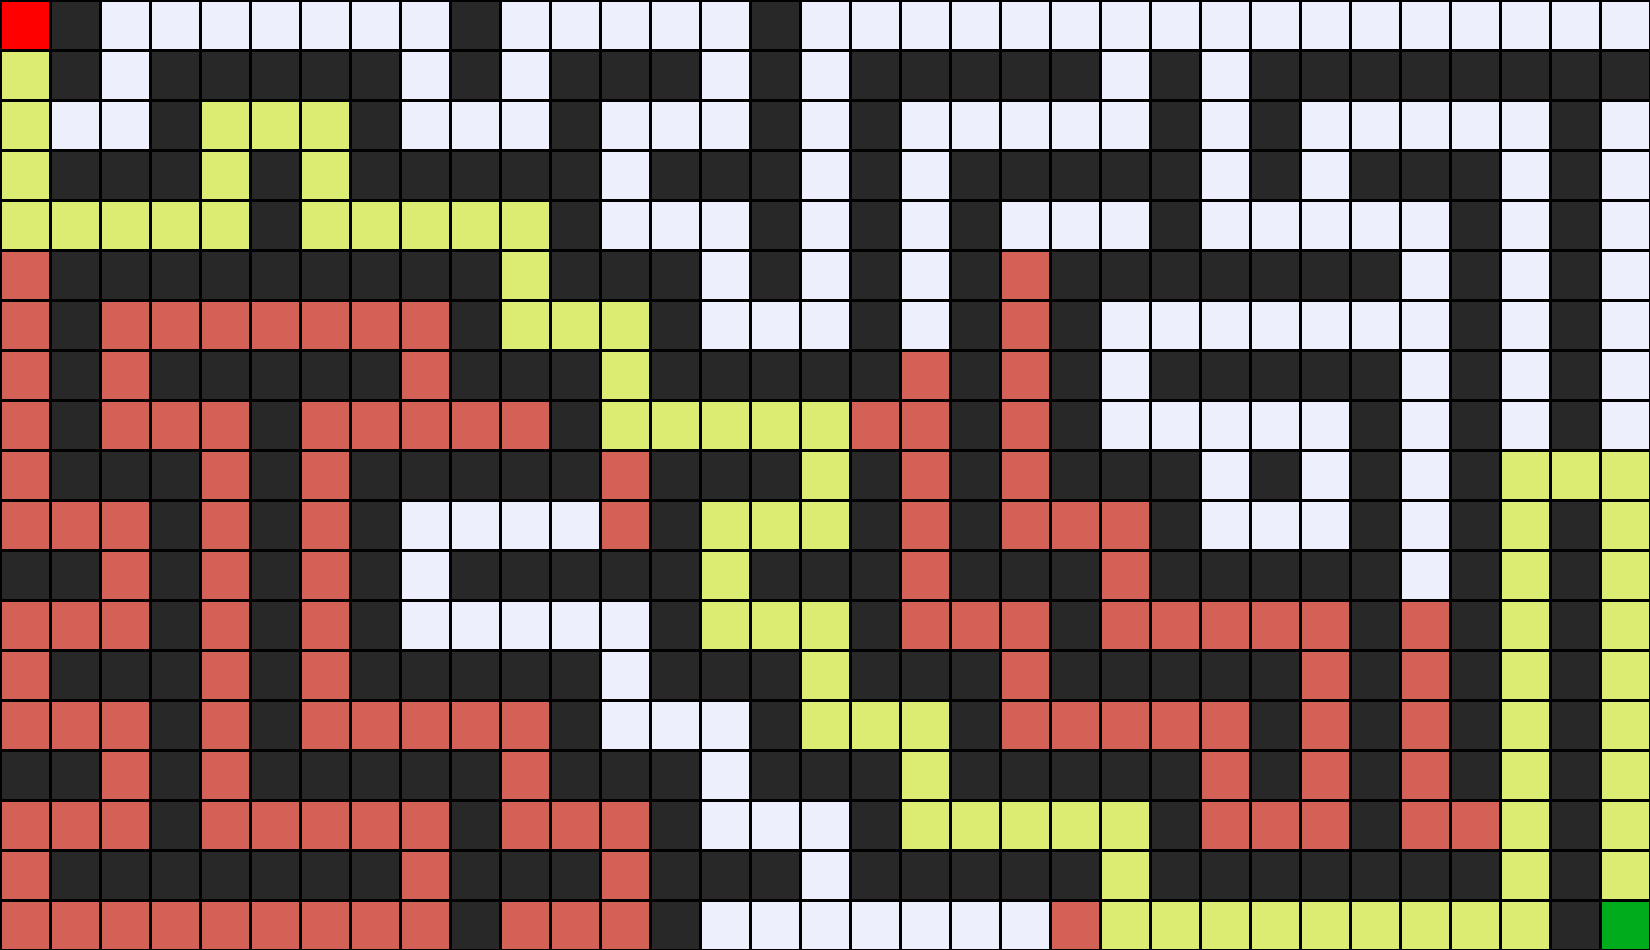

In [101]:
# GBFS
m2_bfs = solve_maze(maze_txt, method="gbfs")

=== Labirinto: data/maze3.txt ===
Maze Inicial:

A█       █     █                 
 █ █████ █ ███ █ █████ █ ████████
   █   █   █   █ █     █ █     █ 
 ███ █ █████ ███ █ █████ █ ███ █ 
     █     █   █ █ █   █     █ █ 
 █████████ ███ █ █ █ ███████ █ █ 
 █       █   █   █ █ █       █ █ 
 █ █████ ███ █████ █ █ █████ █ █ 
 █   █     █       █ █     █ █ █ 
 ███ █ █████ ███ █ █ ███ █ █ █   
   █ █ █     █   █ █   █   █ █ █ 
██ █ █ █ █████ ███ ███ █████ █ █ 
   █ █ █     █   █   █     █ █ █ 
 ███ █ █████ ███ ███ █████ █ █ █ 
   █ █     █   █   █     █ █ █ █ 
██ █ █████ ███ ███ █████ █ █ █ █ 
   █     █   █   █     █   █   █ 
 ███████ ███ ███ █████ ███████ █ 
         █   █                 █B

Solving with ASTAR...
States Explored: 275
Path Cost: 76
Solution:

A█       █     █                 
*█ █████ █ ███ █ █████ █ ████████
*  █***█   █   █ █     █ █     █ 
*███*█*█████ ███ █ █████ █ ███ █ 
*****█*****█   █ █ █   █     █ █ 
 █████████*███ █ █ █ ███████ █ █ 
 █       █***█   █ █ █       █ █

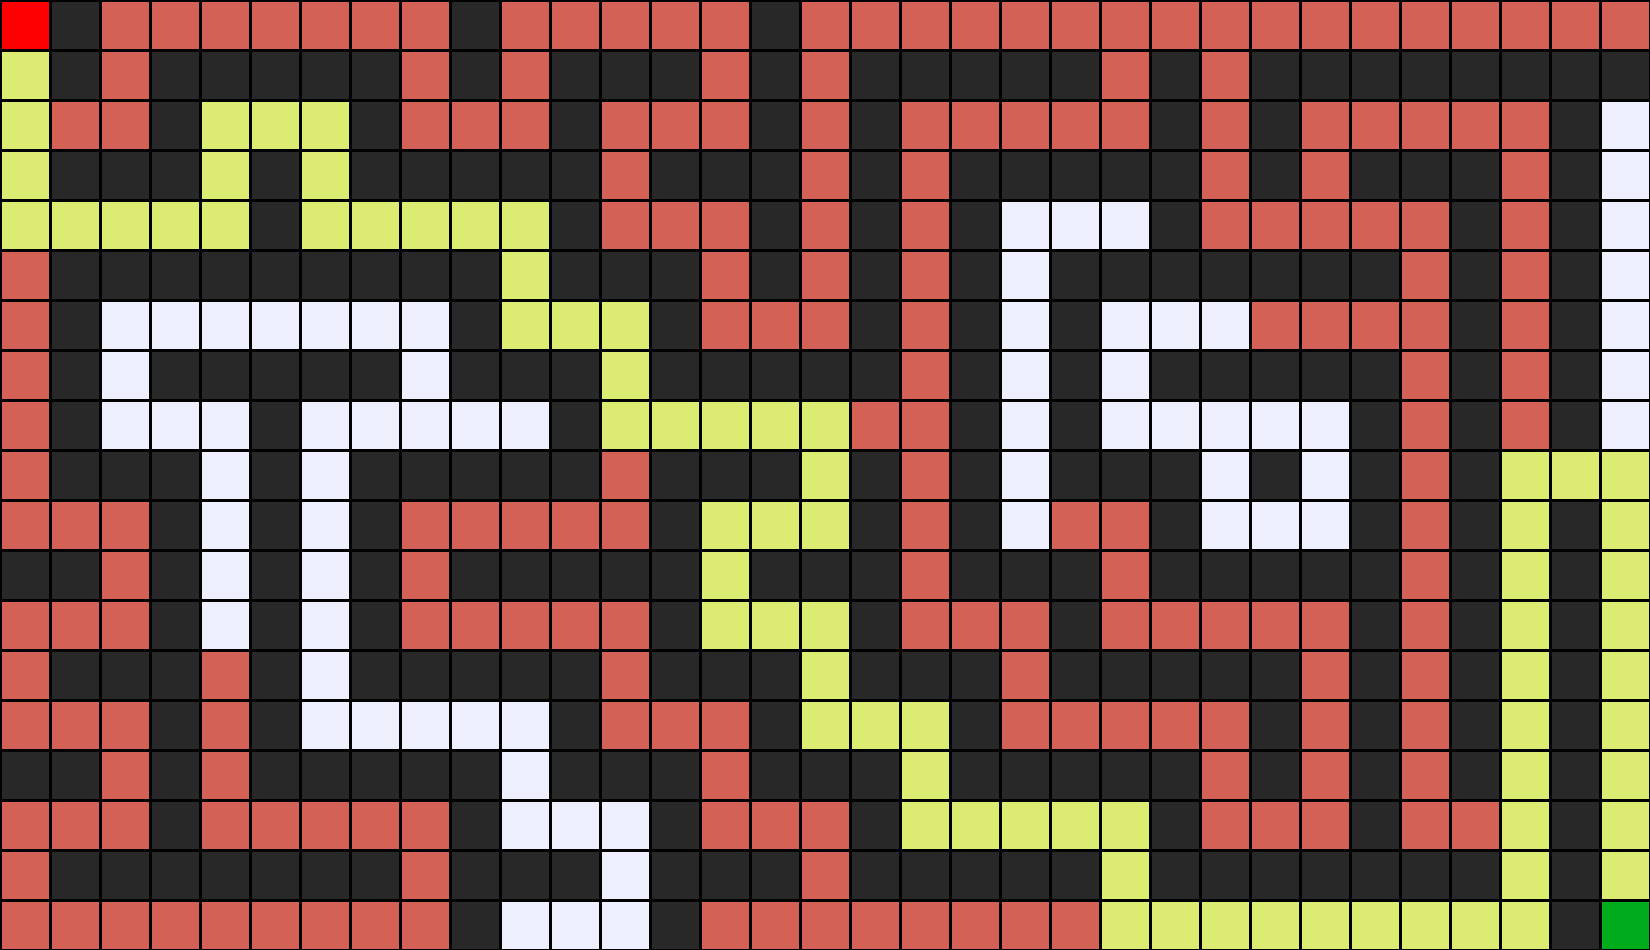

In [102]:
# ASTAR
m2_bfs = solve_maze(maze_txt, method="astar")